In [2]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

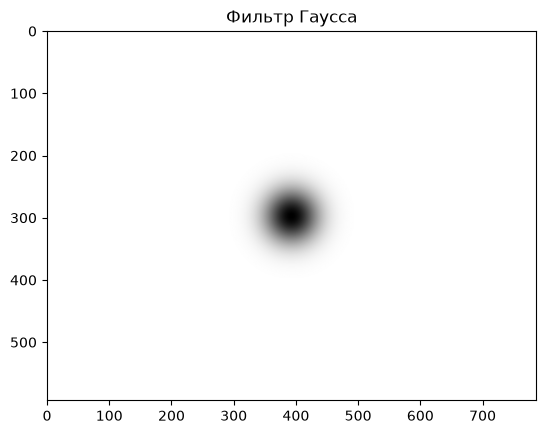

In [13]:
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
D0 = 30
u = np.arange(rows)
v = np.arange(cols)
U, V = np.meshgrid(u - crow, v - ccol, indexing='ij')
D = np.sqrt(U**2 + V**2)
H_low = np.exp(-(D**2) / (2 * D0**2))
H_high = 1 - H_low

plt.imshow(H_high, cmap='gray')
plt.title('Фильтр Гаусса')
plt.show()

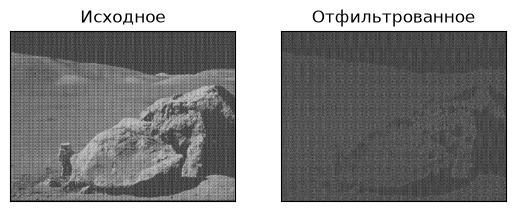

In [14]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
mask_high = np.dstack([H_high, H_high])

fshift_high = dft_shift * mask_high
f_ishift = np.fft.ifftshift(fshift_high)
img_back_high = cv.idft(f_ishift)
img_back_high = cv.magnitude(img_back_high[:,:,0], img_back_high[:,:,1])

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Исходное'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img_back_high, cmap='gray')
plt.title('Отфильтрованное'), plt.xticks([]), plt.yticks([])
plt.show()

In [18]:
ksize = 9
sigma = 2.0
g_1d = cv.getGaussianKernel(ksize, sigma, cv.CV_32F)
kernel = np.outer(g_1d, g_1d)

In [19]:
rows, cols = img.shape
kernel_padded = np.zeros((rows, cols), dtype=np.float32)
kernel_padded[:ksize, :ksize] = kernel
kernel_padded = np.roll(kernel_padded, -ksize // 2, axis=0)
kernel_padded = np.roll(kernel_padded, -ksize // 2, axis=1)
dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)
dft_conv = cv.mulSpectrums(dft_img, dft_kernel, flags=0)
img_back = cv.idft(dft_conv)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])
conv_result = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

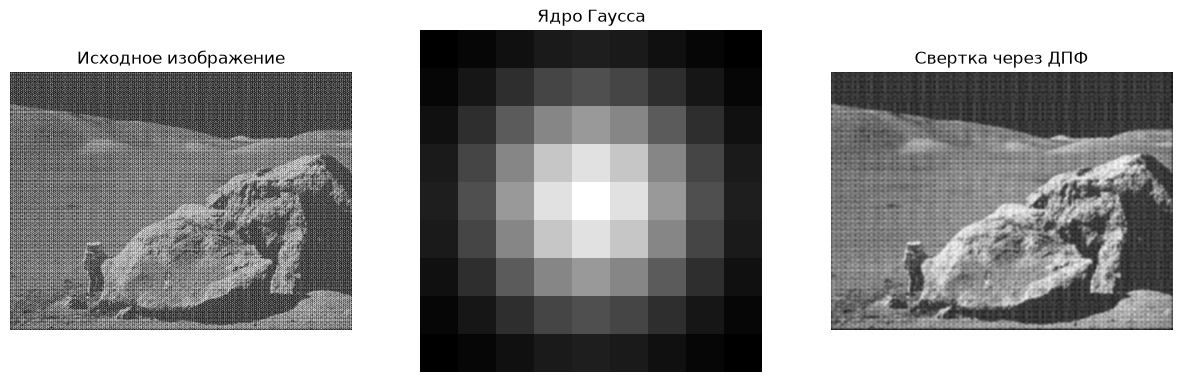

In [20]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Исходное изображение')
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Ядро Гаусса')
plt.imshow(kernel, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Свертка через ДПФ')
plt.imshow(conv_result, cmap='gray')
plt.axis('off')

plt.show()

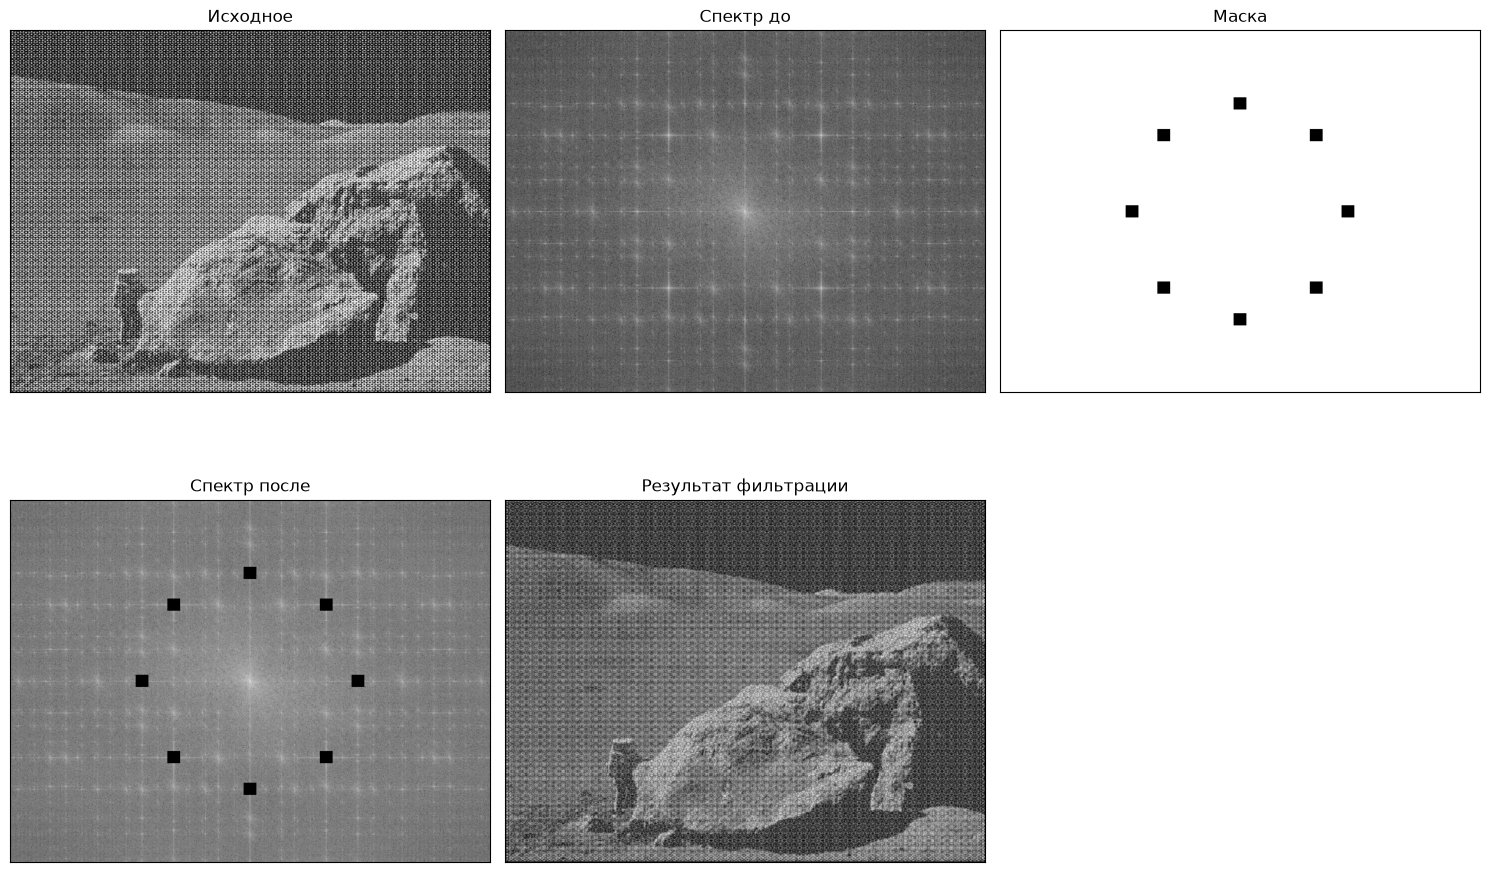

In [4]:
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
spectrum_before = 20 * np.log(1 + cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))
magnitude = cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1])
mag_search = magnitude.copy()
R_center = 30
mag_search[crow-R_center:crow+R_center, ccol-R_center:ccol+R_center] = 0
num_peaks = 8 
flat_idx = np.argsort(mag_search.flatten())[::-1]

peaks = []
for idx in flat_idx:
    y, x = idx // cols, idx % cols
    peaks.append((y, x))
    if len(peaks) == num_peaks:
        break
mask_notch = np.ones((rows, cols), np.float32)
R_notch = 10

for (py, px) in peaks:
    mask_notch[max(0, py-R_notch):min(rows, py+R_notch), 
               max(0, px-R_notch):min(cols, px+R_notch)] = 0
    sy, sx = rows - py, cols - px
    mask_notch[max(0, sy-R_notch):min(rows, sy+R_notch), 
               max(0, sx-R_notch):min(cols, sx+R_notch)] = 0
mask_2ch = np.dstack([mask_notch, mask_notch])
fshift_filtered = dft_shift * mask_2ch
f_ishift = np.fft.ifftshift(fshift_filtered)
spectrum_after = 20 * np.log(1 + cv.magnitude(fshift_filtered[:,:,0], fshift_filtered[:,:,1]))
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])
plt.figure(figsize=(15, 10))

plt.subplot(231), plt.imshow(img, cmap='gray')
plt.title('Исходное'), plt.xticks([]), plt.yticks([])

plt.subplot(232), plt.imshow(spectrum_before, cmap='gray')
plt.title('Спектр до'), plt.xticks([]), plt.yticks([])

plt.subplot(233), plt.imshow(mask_notch, cmap='gray')
plt.title('Маска'), plt.xticks([]), plt.yticks([])

plt.subplot(234), plt.imshow(spectrum_after, cmap='gray')
plt.title('Спектр после'), plt.xticks([]), plt.yticks([])

plt.subplot(235), plt.imshow(img_back, cmap='gray')
plt.title('Результат фильтрации'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()